In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

### Get data

l: quando non ci sono divergenti, distanza tra convergente e schermo

p: distanza tra la divergente e lo schermo prima di muoverlo  
quindi **l-distanza tra divergente e convergente**

q: distanza tra divergente e schermo dopo che è a fuoco  
quindi distanza tra convergente e schermo - p  

In [48]:
import numpy as np

In [49]:
p = np.array([-15.0, -17.0, -19.0, -21.0, -23.0, -25.0, -27.0, -29.0, -31.0, -33.0])  # cm

f_true = 10.0
q = 1 / (1/f_true + 1/p)  # <- use correct formula

In [50]:
inv_p = -1 / p   # make it negative
inv_q = 1 / q

In [51]:
sigma_p = np.full(len(p), 0.00001)
sigma_q = np.full(len(p), 0.00001)

In [52]:
# sigma_p0 = np.full(len(p), 0.01)
# sigma_q0 = np.full(len(p), 0.01)

# Propagate uncertainty (p, sigma_p are arrays)
#sigma_p = np.abs(1 / p**2) * sigma_p0
#sigma_q = np.abs(1 / q**2) * sigma_q0

give both p and q, thus x and y positive sign  
so get as fit a line of m=-1 and ind positive intercept in the first quadrant  
so if one value increase, the other decrease  

note that the intercept, 1/f, must be positive bc it's a convergent lens  

must convert both distance and uncertainty:  

$x_i = \frac{1}{p_i}$  
$\sigma _x = \frac{\sigma _p}{p^2}$  

same for y ad q  

### Fit

$\frac{1}{q} = -\frac{1}{p}+\frac{1}{f}$

y = mx + q  
$y = -x + \frac{1}f$  

can only extimate q  
don't need to extimate m, but put it just to check it's -1  

In [61]:
import numpy as np
from scipy.optimize import curve_fit

# Fix slope = 1, fit only intercept (b = 1/f)
def lens_model(x, m, b):
     return m* x + b

# Fit
popt, pcov = curve_fit(lens_model, inv_p, inv_q)
m = popt[0]
b = popt[1]
focal_length = 1 / b

print(f"Fitted b (1/f): {b:.4f}")
print(f"Estimated focal length f: {focal_length:.2f} cm")
print(m)


Fitted b (1/f): 0.1000
Estimated focal length f: 10.00 cm
-1.0


### Plot

In [ ]:
# x, y, sigma_x, sigma_y
# have popt, pcov

x = inv_p
y = inv_q
sigma_x = sigma_p * 100
sigma_y = sigma_q *100

In [ ]:
res = y - lens_model(x, *popt)

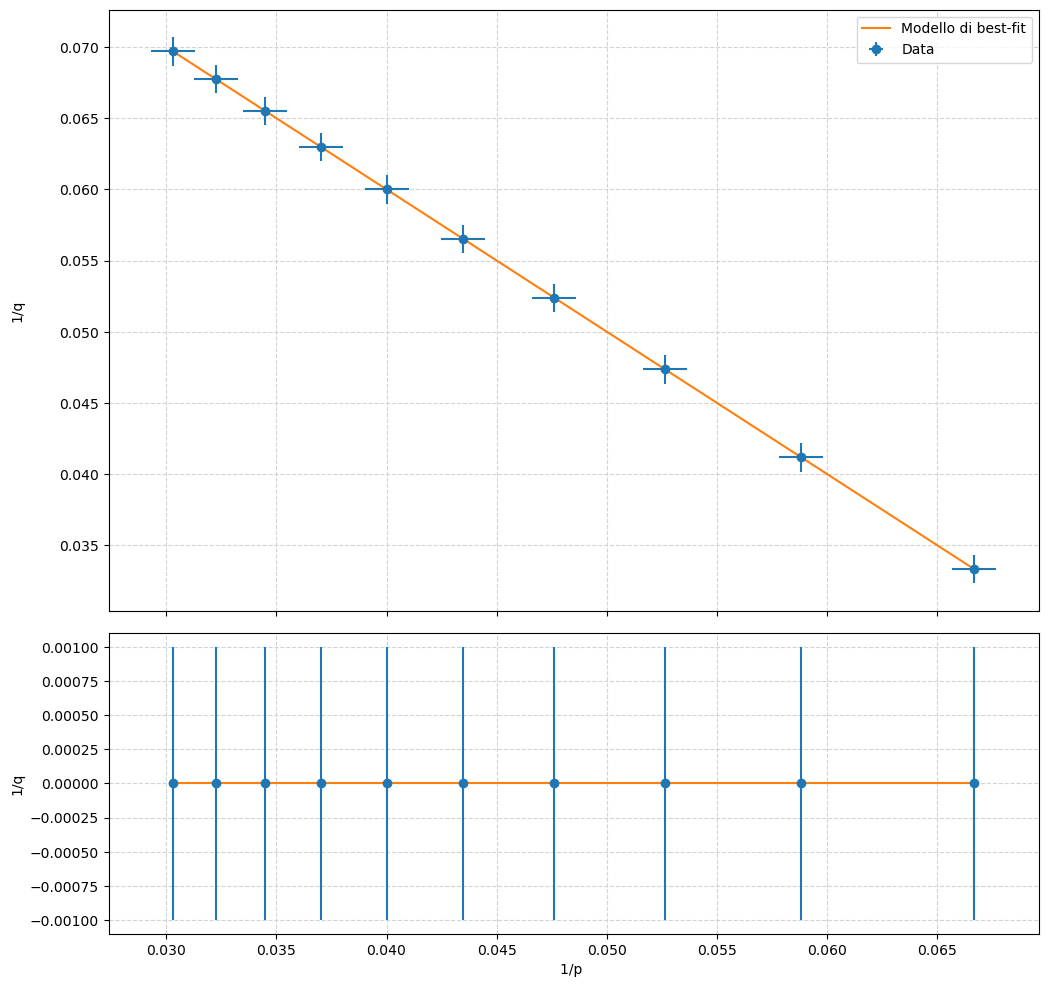

In [66]:
# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, fmt='o', label='Data', yerr=sigma_y, xerr=sigma_x)
xgrid = np.linspace(min(inv_p), max(inv_p), 100)
ax1.plot(xgrid, lens_model(xgrid, *popt), label='Modello di best-fit')

# Setup the axes, grids and legend.
ax1.set_ylabel('1/q')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# Setup the axes, grids and legend.
ax2.set_xlabel('1/p ')
ax2.set_ylabel('1/q')
ax2.grid(color='lightgray', ls='dashed')

# The final touch to main canvas
fig.align_ylabels((ax1, ax2))

plt.show()